# January shortlist

Two roles, from the needs analysis. A penalty-box striker, and a left-back to follow Robertson, who is 32. The left-back search prefers the defensive full-back style.

The pool is the 2025-26 season. A candidate needs 900 minutes, a Transfermarkt match, and he cannot be at Tottenham, including anyone already on the 2026-27 list. Strikers are 27 or under on 1 January 2027. Full-backs are Transfermarkt left-backs, same age cut.

## How to read this

These scores rank candidates for a human scout to review. They are not recommendations on their own. A high score means he looks interesting on last season's numbers. It does not mean Spurs should bid.

Each part is a percentile inside that role's own pool. 100 is the highest in the pool, not the highest in Europe.

- **Value, 40%.** The value model's calibrated gap. A higher percentile means the 2025-26 stats implied a bigger fee than the market, after the cheap-player adjustment.
- **Style fit, 30%.** Cosine similarity between his action profile and the target style: penalty-box striker, or defensive full-back. Actions only. Goals and assists are not in this part.
- **Current form, 20%.** Cosine similarity between his 2026-27 per-90 profile and his own 2025-26 profile. Under 450 minutes this season, this part is set to 50, so a short sample neither helps nor hurts.
- **Reliability, 10%.** 2025-26 minutes as a share of the minutes available to him.

Flags are notes, not points. "Hard to buy in January, maybe a loan" means he is at one of the six richest Premier League squads, or at a club that is top two by squad value in its league. "Cheaper now, or a free transfer in the summer" means the July 2026 Transfermarkt snapshot has his contract ending by June 2027. "No adaptation risk" means he is already in the Premier League. The value date is the date of the fee used in the model, all of them around June 2026.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.shortlist import archetype_profiles, build_shortlist, explain_top_picks

shortlist = build_shortlist()
profiles = archetype_profiles(shortlist)
comparisons = explain_top_picks(shortlist)

LABEL = {
    "shots_per90": "Shots",
    "shot_accuracy": "Shot accuracy",
    "crosses_per90": "Crosses",
    "tackles_won_per90": "Tackles won",
    "interceptions_per90": "Interceptions",
    "fouls_committed_per90": "Fouls",
    "fouls_drawn_per90": "Fouls won",
    "offsides_per90": "Offsides",
    "goals_per90": "Goals",
    "non_penalty_goals_per90": "Non-penalty goals",
    "assists_per90": "Assists",
    "goals_per_shot": "Goals per shot",
    "shots_on_target_per90": "Shots on target",
}
TITLES = {"ST": "Penalty-box striker", "FB": "Left-back to follow Robertson"}

def show_table(need):
    frame = shortlist.loc[shortlist["need"].eq(need)].sort_values("rank")
    table = pd.DataFrame({
        "Rank": frame["rank"].astype(int),
        "Player": frame["player"],
        "2025-26 club": frame["team"],
        "Now": frame["club_now"],
        "Age": frame["age_at_window"].astype(int),
        "Score": frame["total_score"].round(1),
        "Value": frame["value_percentile"].round(0).astype(int),
        "Style": frame["style_percentile"].round(0).astype(int),
        "Form": frame["form_percentile"].round(0).astype(int),
        "Reliability": frame["reliability_percentile"].round(0).astype(int),
        "Flags": frame["flags"].fillna(""),
        "Value date": frame["value_date"],
    })
    display(Markdown(f"### {TITLES[need]}"))
    display(table.style.hide(axis="index"))

Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot
ST: drop shots_on_target_per90 (|r|=0.82 with shots_per90). Shots on target per 90 repeats shot volume, and shot accuracy already keeps the on-target share.
ST: drop shots_on_target_per90 (|r|=0.82 with shots_per90). Shots on target per 90 repeats shot volume, and shot accuracy already keeps the on-target share.
ST: drop shots_on_target_per90 (|r|=0.82 with shots_per90). Shots on target per 90 repeats shot volume, and shot accuracy already keeps the on-target share.


## Penalty-box strikers

Value, style, form, and reliability are percentiles inside the striker pool.

In [2]:
show_table("ST")

### Penalty-box striker

Rank,Player,2025-26 club,Now,Age,Score,Value,Style,Form,Reliability,Flags,Value date
1,Ferran Torres,Barcelona,Paris SG,26,91.200000,96,98,84,65,"Hard to buy in January, maybe a loan. Cheaper now, or a free transfer in the summer.",2026-06-05
2,Donyell Malen,Roma,Roma,27,83.900000,83,91,97,39,,2026-05-29
3,Akor Adams,Sevilla,Venezia,26,82.500000,79,86,92,69,,2026-06-05
4,Ransford Königsdörffer,Hamburger SV,Mainz 05,25,81.600000,99,77,50,89,,2026-05-27
5,Esteban Lepaul,Rennes,Rennes,26,81.500000,76,97,62,95,,2026-06-01
6,Georges Mikautadze,Villarreal,Villarreal,26,79.300000,92,74,68,69,,2026-06-05
7,Cucho,Real Betis,Real Betis,27,76.100000,94,41,86,88,,2026-06-05
8,Anastasios Douvikas,Como,Como,27,72.600000,93,66,41,78,,2026-05-29
9,Vladyslav Vanat,Girona,Girona,24,72.500000,69,94,50,64,,2026-06-05
10,Nicolas Jackson,Bayern Munich,Aston Villa,25,72.400000,77,80,81,16,No adaptation risk.,2026-05-27


## Left-backs

Same four percentiles, inside the left-back pool. The style column is fit to the defensive full-back, so a high score with a low style number is a value pick rather than a stylistic one. Position is Transfermarkt's left-back label.

In [3]:
show_table("FB")

### Left-back to follow Robertson

Rank,Player,2025-26 club,Now,Age,Score,Value,Style,Form,Reliability,Flags,Value date
1,Gabriel Gudmundsson,Leeds United,Leeds United,27,79.900000,81,93,60,74,No adaptation risk.,2026-06-03
2,Álex Valle,Como,Como,22,78.300000,90,97,37,57,,2026-05-29
3,Tyrick Mitchell,Crystal Palace,Crystal Palace,27,76.600000,93,47,77,99,"Cheaper now, or a free transfer in the summer. No adaptation risk.",2026-06-03
4,Neco Williams,Nottingham,Nottingham,25,74.400000,96,56,49,97,No adaptation risk.,2026-06-03
5,Adrien Truffert,Bournemouth,Bournemouth,25,73.700000,66,66,89,100,No adaptation risk.,2026-06-03
6,Sergio Gómez,Real Sociedad,Real Sociedad,26,72.700000,51,94,80,79,,2026-06-05
7,Lewis Hall,Newcastle,Newcastle,22,71.700000,73,54,100,63,"Hard to buy in January, maybe a loan. No adaptation risk.",2026-06-03
8,Adam Obert,Cagliari,Cagliari,24,71.200000,60,74,83,84,,2026-05-29
9,Fabiano Parisi,Fiorentina,Fiorentina,26,69.100000,91,64,50,33,,2026-05-29
10,Juan Miranda,Bologna,Bologna,26,68.100000,76,37,97,73,,2026-05-29


## Top three against the target profile

Bars are 2025-26 action z-scores. The archetype is the average of players in that style. A bar above zero means more of that action than the typical player in the role.

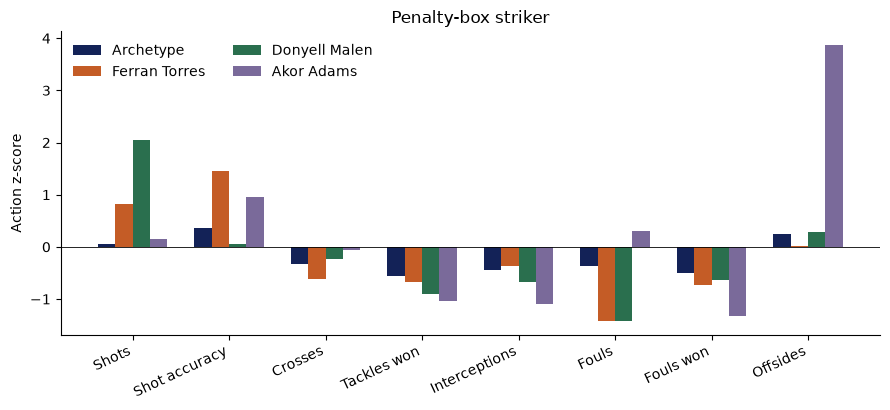

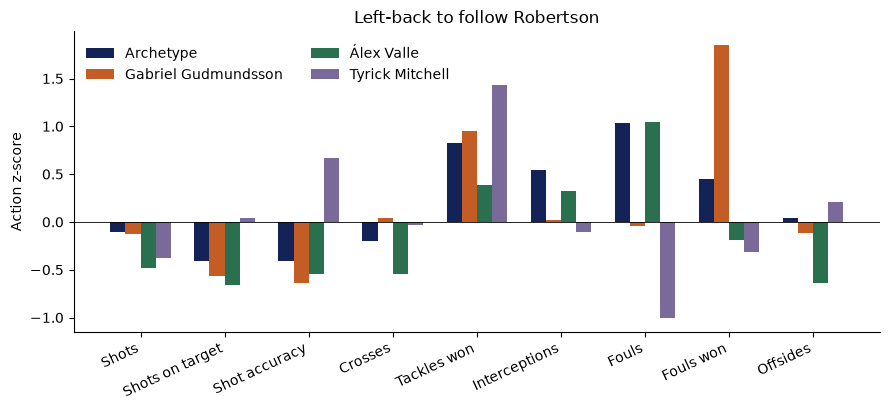

In [4]:
COLORS = ["#132257", "#c45c26", "#2a6f4e", "#7a6a9a"]
for need in ("ST", "FB"):
    frame = profiles.loc[profiles["need"].eq(need)].copy()
    order = [LABEL[name] for name in frame["feature"].drop_duplicates()]
    frame["feature"] = frame["feature"].map(LABEL)
    people = ["Archetype"] + [name for name in frame["who"].drop_duplicates() if name != "Archetype"]
    pivot = frame.pivot(index="feature", columns="who", values="z").loc[order, people]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    width = 0.18
    spots = range(len(pivot.index))
    for index, person in enumerate(people):
        offset = (index - (len(people) - 1) / 2) * width
        ax.bar([spot + offset for spot in spots], pivot[person], width=width, label=person, color=COLORS[index])
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_xticks(list(spots), pivot.index, rotation=25, ha="right")
    ax.set_ylabel("Action z-score")
    ax.set_title(TITLES[need])
    ax.legend(frameon=False, ncol=2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    plt.show()

## Closest benchmark player in the same style

For each of the top three, the comparison is the player at Manchester City, Arsenal, Chelsea, Liverpool, Manchester United, or Newcastle who plays the target style and has the closest action profile. "Alike" is where the z-scores sit nearest. "Apart" is where they sit furthest. The z-scores include goals and assists here, because that is the full player comparison. The style score itself does not.

In [5]:
def phrase(frame):
    if frame.empty:
        return ""
    if "note" in frame.columns and frame["note"].fillna("").iloc[0]:
        return f"**{frame['player'].iloc[0]}.** {frame['note'].iloc[0]}"
    peer = frame["peer"].iloc[0]
    club = frame["peer_team"].iloc[0]
    alike = frame.loc[frame["kind"].eq("alike"), "feature"].map(LABEL).tolist()
    apart = frame.loc[frame["kind"].eq("different"), "feature"].map(LABEL).tolist()
    return (
        f"**{frame['player'].iloc[0]}** is closest to **{peer}** ({club}). "
        f"Alike on {', '.join(alike)}. Apart on {', '.join(apart)}."
    )

lines = []
for need in ("ST", "FB"):
    lines.append(f"### {TITLES[need]}")
    picks = shortlist.loc[shortlist["need"].eq(need)].nsmallest(3, "rank")
    for player in picks["player"]:
        lines.append(phrase(comparisons.loc[comparisons["need"].eq(need) & comparisons["player"].eq(player)]))
display(Markdown("\n\n".join(lines)))

### Penalty-box striker

**Ferran Torres** is closest to **Benjamin Šeško** (Manchester Utd). Alike on Crosses, Interceptions, Shots. Apart on Fouls won, Goals per shot, Non-penalty goals.

**Donyell Malen** is closest to **Erling Haaland** (Manchester City). Alike on Tackles won, Interceptions, Fouls. Apart on Offsides, Assists, Shot accuracy.

**Akor Adams** is closest to **Benjamin Šeško** (Manchester Utd). Alike on Tackles won, Goals per shot, Fouls won. Apart on Offsides, Non-penalty goals, Shots on target.

### Left-back to follow Robertson

**Gabriel Gudmundsson** is closest to **Conor Bradley** (Liverpool). Alike on Goals, Non-penalty goals, Goals per shot. Apart on Fouls, Assists, Shot accuracy.

**Álex Valle** is closest to **Conor Bradley** (Liverpool). Alike on Crosses, Tackles won, Shots. Apart on Fouls won, Goals per shot, Shot accuracy.

**Tyrick Mitchell** is closest to **Rayan Aït-Nouri** (Manchester City). Alike on Shots on target, Fouls won, Tackles won. Apart on Fouls, Assists, Offsides.

## Limitations

Every fee in the value score is from around June 2026. A lot can change in a valuation between then and a January bid. The model uses basic per-90 counts, not chance quality or where on the pitch the actions happen.

The backtest of this value model found no reliable edge over the market. A high value percentile is a reason to watch someone, not a reason to assume the fee is wrong.

Form compares the shape of two per-90 profiles. A player who is quieter this season but in the same proportions will not look like he has dropped off, because cosine similarity ignores a change in scale. Samples under 450 minutes are parked at 50. Contract dates are the July 2026 Transfermarkt snapshot.